# **Airplane Boarding Strategy Agent-Based Model**

## Project Overview
> In this project, our group developed an Agent-Based Model (ABM) to study how different airplane boarding strategies impact the total time required to seat all passengers.
> Instead of treating passengers as one large system, we model each individual as an agent with their own seat assignment, movement rules, and luggage-handling behavior. This allows us to capture realistic situations such as aisle congestion, seat-access delays, and movement conflicts.
>
> *Leading us to our research question:*


## ***What is the best strategy to board passengers on a plane?***


In [1]:
#Importing Packages
import random
import time #from HW02 
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch #from HW02 show function
from IPython.display import clear_output #from HW02 

## Classes 
### Passenger Class:
> The Passenger class defines the properties and behavior of each individual boarding the plane.
> One person stopping to handle luggage slows down everyone behind them.
> Window-seat passengers force others to move sideways.
> Multiple passengers competing for the same aisle cell creates traffic.

In [2]:
class Passenger:
    def __init__(self, pid, row, seat, luggage_delay=None):
        self.pid = pid # Unique passenger ID number (e.g., 1, 2, 3...)
        self.row = row # The target row where the passenger will sit (Row 1–9 on our simulate model)
        self.seat = seat # The seat column name assigned to the passenger (A, B, C, D, E, or F)
        self.x = -1 # Current x-position in the aisle, we set x=-1 to indicate that a passenger has not entered yet
        self.y = None # Current y-position (column index), which will be set when the passenger enters the plane.
        self.seated = False # Will be used to define whether a passenger is already seated (either True or False)
        self.luggage_delay = random.randint(9, 12) # Set number of steps needed to place luggage in the overhead bin. At least 9 seconds and at most 12 seconds to place 1 luggage
        self.remaining_delay = self.luggage_delay # Remaining luggage time in seconds (counts down as simulation runs)

    def __repr__(self):
        return f"Passenger(row={self.row}, seat={self.seat}, seated={self.seated})" #learned from cell class in HW02

### Plane Class:
> The Plane class represents the environment in which all passengers move.
> It stores the plane’s layout, handles seat assignments, manages movement rules, and updates the system at each time-step.

In [3]:
class Plane:
    def __init__(self, num_rows):
        self.num_rows = num_rows
        self.seat_letters = ["A", "B", "C", "D", "E", "F"]
        self.aisle_y = 3
        self.entrance_y = 3

        # plane state
        self.passengers = []

        # seat map
        self.seats = {}
        for row in range(1, num_rows + 1):
            for seat in self.seat_letters:
                self.seats[(row, seat)] = None

    # seat letter indicates y coordinate
    def get_seat_y(self, seat):
        return {"A": 0, "B": 1, "C": 2, "D": 4, "E": 5, "F": 6}[seat]

    # add passenger to queue
    def add_passenger(self, passenger):
        passenger.x = -1
        passenger.y = self.entrance_y
        self.passengers.append(passenger)

    # sit a passenger (fill seat)
    def sit_passenger(self, passenger):
        if self.seats[(passenger.row, passenger.seat)] is None:
            self.seats[(passenger.row, passenger.seat)] = passenger
            passenger.seated = True
            return True
        return False

    # generates a list of passengers by assigning each seat to a passenger pid
    def make_passengers(self):
        passengers = []
        pid = 1
        for row in range(1, self.num_rows + 1):
            for seat in self.seat_letters:
                passengers.append(Passenger(pid, row, seat))
                pid += 1
        return passengers

    # Updated step() funtion which avoid queuing conflict
    def step(self):

        intentions = {}

        # order of movement follows queue order
        order = {p: i for i, p in enumerate(self.passengers)}

        # cells currently occupied (only aisle movers, not seated ones)
        occupied = {(p.x, p.y) for p in self.passengers
                    if (not p.seated and p.x >= 0)}

        movers = [p for p in self.passengers if not p.seated]

        for p in movers:

            # Stage 1. entering plane
            if p.x < 0:
                target = (0, self.aisle_y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 2. walk forward in aisle until (row-1, aisle)
            if p.x < p.row - 1:
                nx = p.x + 1
                target = (nx, p.y)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 3. step sideways toward seat
            seat_y = self.get_seat_y(p.seat)

            if p.y < seat_y:
                target = (p.x, p.y + 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            if p.y > seat_y:
                target = (p.x, p.y - 1)
                if target not in occupied:
                    intentions[p] = target
                else:
                    intentions[p] = (p.x, p.y)
                continue

            # Stage 4. luggage delay
            if p.remaining_delay > 0:
                p.remaining_delay -= 1
                intentions[p] = (p.x, p.y)
                continue

            # Stage 5. sit down
            self.sit_passenger(p)
            intentions[p] = (p.x, p.y)

        cell_to_list = {}
        for p, cell in intentions.items():
            cell_to_list.setdefault(cell, []).append(p)

        # apply moves
        for cell, plist in cell_to_list.items():
            if len(plist) == 1:
                p = plist[0]
                if not p.seated:
                    p.x, p.y = cell
            else:
                # choose winner by queue order
                winner = min(plist, key=lambda x: order[x])
                if not winner.seated:
                    winner.x, winner.y = cell
                # losers remain

    # animate run() with plot
    def run(self):
        start = time.time()
        step_count = 0
        while not all(p.seated for p in self.passengers):
            clear_output(wait=True)
            self.show()
            self.step()
            step_count += 1
            time.sleep(0.1)

        clear_output(wait=True)
        self.show()
        end = time.time()
        time_elapsed = end - start
        minutes = int(time_elapsed // 60)
        seconds = time_elapsed % 60

        if minutes > 0:
            print(f"It took {minutes} minute{'s' if minutes != 1 else ''} and {round(seconds, 2)} seconds to board the plane!")
        else:
            print(f"It took {round(seconds, 2)} seconds to board the plane!")

    # fast mode: Run simulation without plotting, accumulating REAL boarding time.
    # Each step represents `seconds_per_step` real seconds.
    def run_no_plot(self, seconds_per_step=0.5):
        total_time = 0.0

        while not all(p.seated for p in self.passengers):
            self.step()
            total_time += seconds_per_step

        return total_time

    # visualization (original)
    def show(self):
        for (row, seat), passenger in self.seats.items():
            y = self.get_seat_y(seat)
            color = "green" if passenger else "white"
            plt.scatter(row - 1, y, s=500, c=color, edgecolors='black')

        for p in self.passengers:
            if not p.seated:
                plt.scatter(p.x, p.y, s=500, c='red', edgecolors='black')

        plt.grid()
        plt.xticks(range(self.num_rows))
        plt.yticks(range(7))
        plt.xlim(-1, self.num_rows)
        plt.ylim(-1, 7)
        plt.show()

## Testing the Model Layout on a Small board 
>Before scaling our simulation to the full aircraft model, we first run a small 3-row version to confirm that the core logic works correctly. This test helps us verify passenger movement, aisle behavior, collision, and seating mechanics in a simplified environment. By ensuring the model behaves as expected at a smaller scale, we can confidently extend it to the full plane layout.

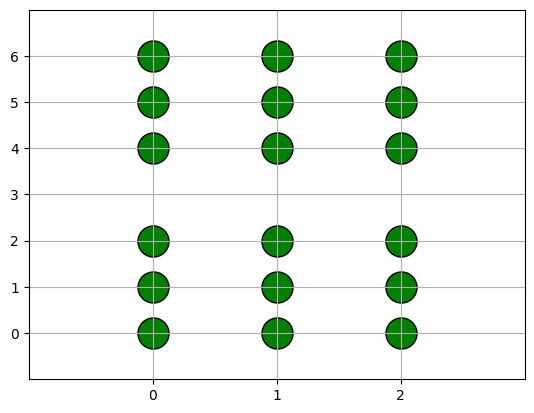

It took 28.3 seconds to board the plane!


In [6]:
boeing = Plane(num_rows=3)

# Genreate 3 rows × A–F = 18 passengers
passengers = boeing.make_passengers()

for p in passengers:
    boeing.add_passenger(p)

boeing.run()

# Full Boarding Simulation using on 20-Row Boeing Layout to test different methods
> Running this full-scale simulation allows us to evaluate how well this strategy performs under real-size aircraft conditions and compare it to other boarding methods.
## 1. Front-to-Back Boarding Method
> Passengers are sorted by row first and then by seat type to reduce aisle interference and minimize seat-access conflicts. In a Window → Middle → Aisle sequence.

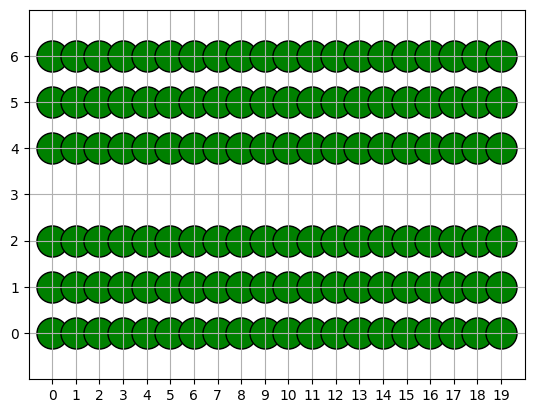

It took 5 minutes and 21.99 seconds to board the plane!


In [7]:
full_boeing = Plane(num_rows=20)

passengers = full_boeing.make_passengers()

window = ["A", "F"]
middle = ["B", "E"]
aisle  = ["C", "D"]

# Front-to-Back + Window→Middle→Aisle
ordered = sorted(
    passengers,
    key=lambda p: (
        p.row, 
        0 if p.seat in window else
        1 if p.seat in middle else
        2,
        p.seat
    )
)

for p in ordered:
    full_boeing.add_passenger(p)

full_boeing.run()

## 2. Back-to-Front Boarding Method
> In this simulation, we apply the reverse of the previous strategy by boarding passengers from the back of the plane to the front while still prioritizing seats in the order Window → Middle → Aisle. This approach is commonly discussed as a way to reduce aisle congestion, since passengers heading to the rear enter first and avoid blocking others behind them.

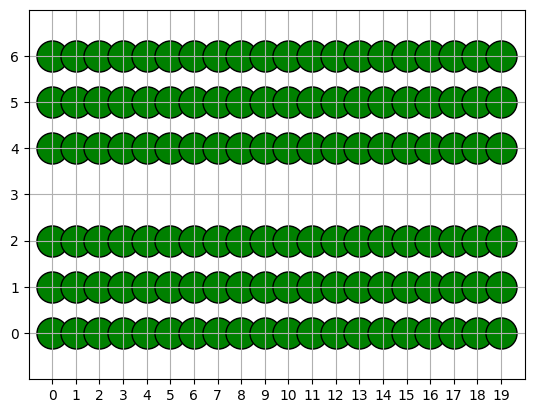

It took 5 minutes and 14.26 seconds to board the plane!


In [5]:
full_reverse_order_boeing = Plane(num_rows=20)

# automatically generate 20 rows × 6 seats = 120 passengers
passengers = full_reverse_order_boeing.make_passengers()

# Seat priority: window first, then middle, finally aisle
seat_priority = {
    "A": 0, "F": 0, # window seat first
    "B": 1, "E": 1, # middle seat then
    "C": 2, "D": 2 # aisle seat final
}

reverse_order = sorted(
    passengers,
    key=lambda p: (
        -p.row,                # 1. from back to front
        seat_priority[p.seat], # 2. window first, then middle, finally aisle
        p.seat                 # 3. alphabetical order within seat group
    )
)

# make passengers enter the plane in reverse_order
for p in reverse_order:
    full_reverse_order_boeing.add_passenger(p)
    
# run simulation
full_reverse_order_boeing.run()

### As shown in the previous simulation, boarding passengers from the back of the plane while prioritizing window-to-aisle seating resulted in noticeably higher efficiency.

## 3. WILMA (window → middle → aisle) Boarding Method 
> According to the reference listed below, the WILMA method boards all window-seat passengers first, followed by middle-seat passengers, and finally aisle-seat passengers. The idea behind WILMA is to minimize seat-access conflicts early in the process and reduce slowdowns caused by passengers needing to pass each other in the row.
> **Reference:
https://boardingarea.com/all-about-uniteds-new-wilma-boarding-for-frequent-flyers/**

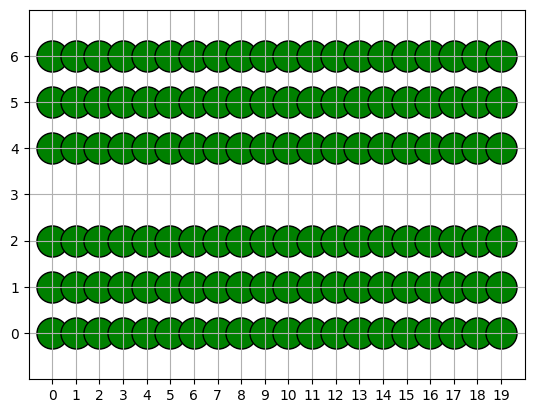

It took 5 minutes and 14.23 seconds to board the plane!


In [6]:
# WILMA: The WILMA boarding method loads passengers strictly by seat type: all window-seat passengers board first, followed by all middle-seat passengers, and finally all aisle-seat passengers.

wilma_boeing = Plane(num_rows=20)

# automatically generate 20 rows × 6 seats = 120 passengers
passengers = wilma_boeing.make_passengers()

window_seats = ["A", "F"]
middle_seats = ["B", "E"]
aisle_seats  = ["C", "D"]

# WILMA order
wilma_sorted = sorted(
    passengers,
    key=lambda p: (
        0 if p.seat in window_seats else
        1 if p.seat in middle_seats else
        2,      # seat group：from window to middle, finally aisle
        -p.row  # row：back → front
    )
)

# make passengers enter the plane in wilma_sorted order
for p in wilma_sorted:
    wilma_boeing.add_passenger(p)

# run simulation
wilma_boeing.run()

### Our results indicate that the WILMA boarding method is faster than the strategies we previously tested.
To extend our analysis, the article linked below introduces two additional boarding approaches—*the Southwest method and the Steffen method—* both of which are widely discussed for their potential efficiency improvements. 
 **Reference: https://www.vox.com/2014/4/25/5647696/the-way-we-board-airplanes-makes-absolutely-no-sense**

## 4. Southwest Boarding Method
> Southwest uses an open-seating system where passengers choose any available seat as they board. To approximate this in our simulation, we randomly shuffle all seat positions in the plane and assign passengers to these seats without any structured order. This captures the “first come, first served” nature of Southwest’s boarding style.

In [7]:
def southwest_random_seat_assignment(num_rows=20):

    seat_letters = ["A", "B", "C", "D", "E", "F"]

    # All possible seats (row, seat)
    seats = [
        (row, seat)
        for row in range(1, num_rows + 1)
        for seat in seat_letters
    ]

    # Randomize seat positions
    random.shuffle(seats)

    # Create passengers with shuffled seat assignments
    passengers = []
    for pid, (row, seat) in enumerate(seats, start=1):
        passengers.append(Passenger(pid, row, seat))

    return passengers

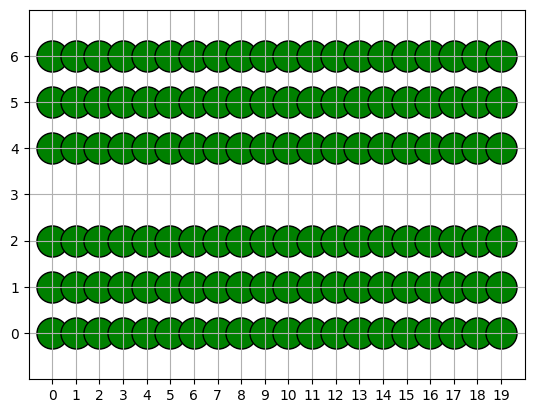

It took 5 minutes and 26.94 seconds to board the plane!


In [8]:
sw_passengers = southwest_random_seat_assignment()

sw_boeing = Plane(num_rows=20)

for p in sw_passengers:
    sw_boeing.add_passenger(p)

sw_boeing.run()

## 5. Steffen Boarding Method
>The Steffen method is a highly structured boarding strategy designed to minimize aisle interference and seat-access delays. To simulate this approach, we prioritize passengers by seat type (Window → Middle → Aisle) and then apply an alternating-row pattern within each group. Passengers in odd-numbered rows board first, followed by those in even-numbered rows, and both groups are sorted from back to front. This staggered ordering spaces passengers out along the aisle, reducing blocking and allowing multiple people to store luggage simultaneously.

In [22]:
#AI-assisted completion of the Steffen boarding method implementation
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Note: A portion of this method required clarification regarding the correct ordering logic 
#(seat-group priority and alternating-row structure), so assistance was used to refine and 
#complete the final implementation.
def steffen_sort(group):
    """
    Sort a seat-type group using Steffen's alternating-row logic:
    - Separate passengers into odd vs. even rows
    - Sort each list from back to front
    - Return odd rows first, then even rows
    """

    odd_rows  = [p for p in group if p.row % 2 == 1]
    even_rows = [p for p in group if p.row % 2 == 0]

    # Back-to-front sorting (descending row number)
    odd_rows.sort(key=lambda p: -p.row)
    even_rows.sort(key=lambda p: -p.row)

    return odd_rows + even_rows

def steffen_boarding(passengers):
    """
    Jason Steffen boarding method (optimized boarding):
    1) Prioritize seat groups in the order: Window (A/F) → Middle (B/E) → Aisle (C/D)
    2) Within each seat group, apply an 'alternating row' pattern:
          Odd-numbered rows first, Even-numbered rows will become the alternating row
    3) Both odd and even groups are sorted back-to-front (higher row → lower row) based on our experience
    """

    window = ["A", "F"]
    middle = ["B", "E"]
    aisle  = ["C", "D"]
    
    # Categorize passengers by seat type
    window_ps = [p for p in passengers if p.seat in window]
    middle_ps = [p for p in passengers if p.seat in middle]
    aisle_ps  = [p for p in passengers if p.seat in aisle]

    # Apply Steffen ordering for each seat category
    ordered = []
    ordered += steffen_sort(window_ps)
    ordered += steffen_sort(middle_ps)
    ordered += steffen_sort(aisle_ps)

    return ordered

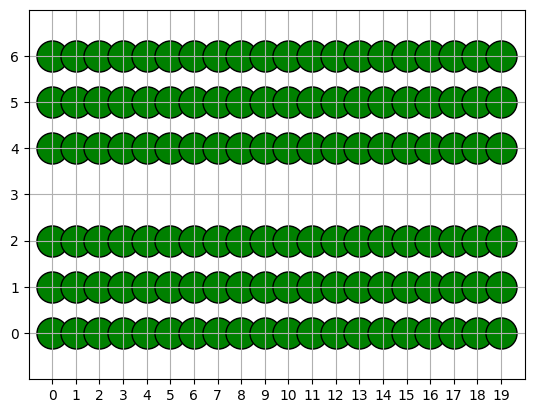

It took 5 minutes and 18.51 seconds to board the plane!


In [23]:
steffen_boeing = Plane(20)
passengers = steffen_boeing.make_passengers()
ordered = steffen_boarding(passengers)
for p in ordered:
    steffen_boeing.add_passenger(p)

steffen_boeing.run()

#### Our initial results show that the time difference between the Steffen method and the WILMA method is relatively small. 
To better evaluate their performance, we will run both simulations 1,000 times with randomized conditions and compare their average boarding times.

In [11]:
#AI-generated code for applying multiple boarding strategies (similar to R's apply)
#Source: OpenAI. (2025). ChatGPT-5. Accessed from https://chatgpt.com/ on Nov 20, 2025
#Prompt: "I am writing a function which applies several plane boarding strategies using a list of 
# functions, runs each strategy 1000 times with random passengers. Could you please help me deal with the for loop so that it can compute the average 
# boarding time using measure_strategy(), and returns all results in a clean dictionary or table."

def measure_strategy(strategy_function, n=100, num_rows=20, seconds_per_step=0.5):
    total = 0

    for _ in range(n):

        plane = Plane(num_rows)

        # Try queue-based strategy first (expects passengers)
        try:
            passengers = plane.make_passengers()
            ordered = strategy_function(passengers)

        # If fails, then it's Southwest (expects num_rows)
        except TypeError:
            ordered = strategy_function(num_rows)

        # Load passengers
        for p in ordered:
            plane.add_passenger(p)

        total += plane.run_no_plot(seconds_per_step)

    avg = total / n
    minutes = int(avg // 60)
    seconds = avg % 60

    if minutes > 0:
        time_str = f"{minutes} minute{'s' if minutes != 1 else ''} and {seconds:.2f} seconds"
    else:
        time_str = f"{seconds:.2f} seconds"

    print(f"{strategy_function.__name__}: average = {time_str} over {n} runs")

In [12]:
# This is a simple function for WILMA Method which all Window seats board first, followed by middle seats, and aisle seats last.
# Within each seat group, passengers board from back to front to minimize aisle congestion.
def wilma_boarding(passengers):
    window_seats = ["A", "F"]
    middle_seats = ["B", "E"]
    aisle_seats = ["C", "D"]

    # WILMA = Window, then Middle, then Aisle
    sorted_list = sorted(
        passengers,
        key=lambda p: (
            0 if p.seat in window_seats else
            1 if p.seat in middle_seats else
            2,
            -p.row
        )
    )
    return sorted_list

In [39]:
# This is a simple function for the front-to-back method which the window seat, middle seat, then aisle seat of the first row boards first.
# The same pattern continues for the next row until the plane is full
# Created by modifying the wilma_boarding function

def front_to_back_boarding(passengers):
    """
    Return list of passengers ordered by rows from front to back
    Seats in order: window (A,F), then middle (B,E), then aisle (C,D).
    """
    window_seats = ["A", "F"]
    middle_seats = ["B", "E"]
    aisle_seats  = ["C", "D"]

    sorted_list = sorted(
        passengers,
        key=lambda p: (
            0 if p.seat in window_seats else
            1 if p.seat in middle_seats else
            2,
            p.row   # front to back
        )
    )
    return sorted_list

In [40]:
# This is a simple function for the back-to-front method which the window seat, middle seat, then aisle seat of the last row boards first.
# The same pattern continues for the next row moving closer to the front until the plane is full
# Created by modifying the wilma_boarding function

def back_to_front_boarding(passengers):
    """
    Return list of passengers ordered by rows from back to front
    Seats in order: window (A,F), then middle (B,E), then aisle (C,D).
    """
    window_seats = ["A", "F"]
    middle_seats = ["B", "E"]
    aisle_seats  = ["C", "D"]

    sorted_list = sorted(
        passengers,
        key=lambda p: (
            0 if p.seat in window_seats else
            1 if p.seat in middle_seats else
            2,
            -p.row   # back to front
        )
    )
    return sorted_list

In [13]:
measure_strategy(wilma_boarding, n=1000, seconds_per_step=1.5)

wilma_boarding: average = 6 minutes and 17.24 seconds over 1000 runs


In [14]:
measure_strategy(southwest_random_seat_assignment, n=1000,seconds_per_step=1.5)

southwest_random_seat_assignment: average = 6 minutes and 52.41 seconds over 1000 runs


In [15]:
measure_strategy(steffen_boarding, n=1000,seconds_per_step=1.5)

steffen_boarding: average = 6 minutes and 18.91 seconds over 1000 runs


In [41]:
measure_strategy(front_to_back_boarding, n=1000,seconds_per_step=1.5)

front_to_back_boarding: average = 6 minutes and 45.82 seconds over 1000 runs


In [42]:
measure_strategy(back_to_front_boarding, n=1000,seconds_per_step=1.5)

back_to_front_boarding: average = 6 minutes and 17.35 seconds over 1000 runs


## Visualizing Our Results

Now that we have results for our stochastic and single run deterministic models, let's create a chart to view the results.

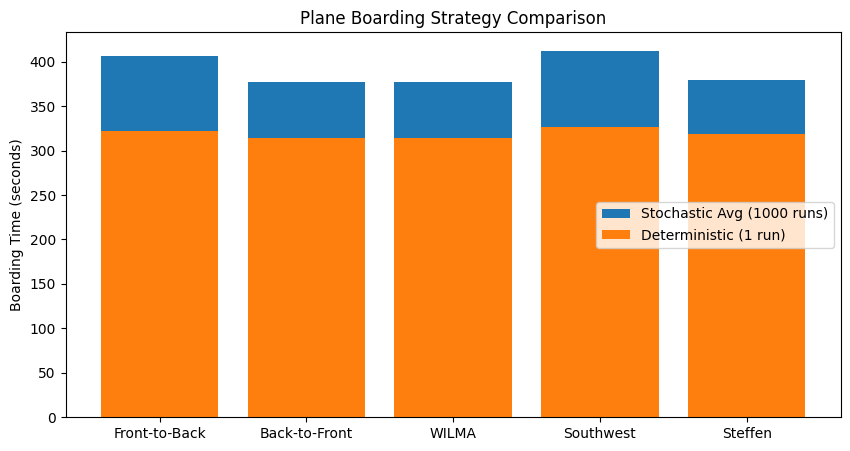

In [50]:
strategies = ["Front-to-Back", "Back-to-Front", "WILMA", "Southwest", "Steffen"]
stochastic = [6*60 + 45.82, 6*60 + 17.35, 6*60 + 17.24, 6*60 + 52.41, 6*60 + 18.91]
deterministic = [5*60 + 21.99, 5*60 + 14.26, 5*60 + 14.23, 5*60 + 26.94, 5*60 + 18.51]

# Plot bars
plt.figure(figsize=(10,5))
plt.bar(strategies, stochastic, label = "Stochastic Avg (1000 runs)")
plt.bar(strategies, deterministic, label = "Deterministic (1 run)")

plt.ylabel("Boarding Time (seconds)")
plt.title("Plane Boarding Strategy Comparison")
plt.legend(loc="center right")
plt.show()

#### We see that there is greater variation between the results of the stochastic averages compared to the deterministic testing we did earlier. Based on the average boarding times calculated across 1,000 randomized simulations, our results suggest that the WILMA method is the most efficient strategy for boarding passengers.

## Conclusion
>Through our simulations and repeated trials, we evaluated several boarding strategies, including back-to-front ordering, WILMA, Southwest’s open seating, and the Steffen method. While multiple approaches showed improvements over random boarding, **our averaged results across 1,000 runs indicate that the WILMA method consistently produces the fastest boarding times.** This suggests that prioritizing seat groups from window to aisle effectively reduces aisle congestion and seat-access conflicts, making it one of the most efficient strategies for boarding a full aircraft. Notably, the Back-to-Front and Steffen methods produced very similar results. The Southwest method showed to be an inefficient method of boarding planes, and boarding front to back is also not ideal.